In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("uber.csv")
print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [6]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Statistical Summary:


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000



Duplicate Rows: 0


In [7]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

df = df.dropna().drop_duplicates()

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df = df.dropna(subset=["pickup_datetime"])

# Remove invalid fares and passenger counts
df = df[
    (df["fare_amount"] > 0) &
    (df["fare_amount"] <= 100) &
    (df["passenger_count"].between(1, 6))
].copy()

print("Shape after preprocessing:", df.shape)
display(df.head())

Shape after preprocessing: (199184, 7)


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


In [ ]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2

    return 2 * R * np.arcsin(np.sqrt(a))

    


df["distance"] = haversine(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Keep valid geographic coordinates and plausible ride distances
df = df[
    df["pickup_latitude"].between(-90, 90) &
    df["dropoff_latitude"].between(-90, 90) &
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180) &
    (df["distance"] > 0) &
    (df["distance"] <= 100)
].copy()

print("Dataset shape after distance calculation:", df.shape)
display(df[["distance", "fare_amount"]].head())

Dataset shape after distance calculation: (193120, 8)


,distance,fare_amount
0,1.683323,7.5
1,2.457590,7.7
2,5.036377,12.9
3,1.661683,5.3
4,4.475450,16.0


In [9]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek

print("Time features created successfully.")
display(df[["hour", "day", "month", "year", "day_of_week"]].head())

Time features created successfully.


,hour,day,month,year,day_of_week
0,19,7,5,2015,3
1,20,17,7,2009,4
2,21,24,8,2009,0
3,8,26,6,2009,4
4,17,28,8,2014,3


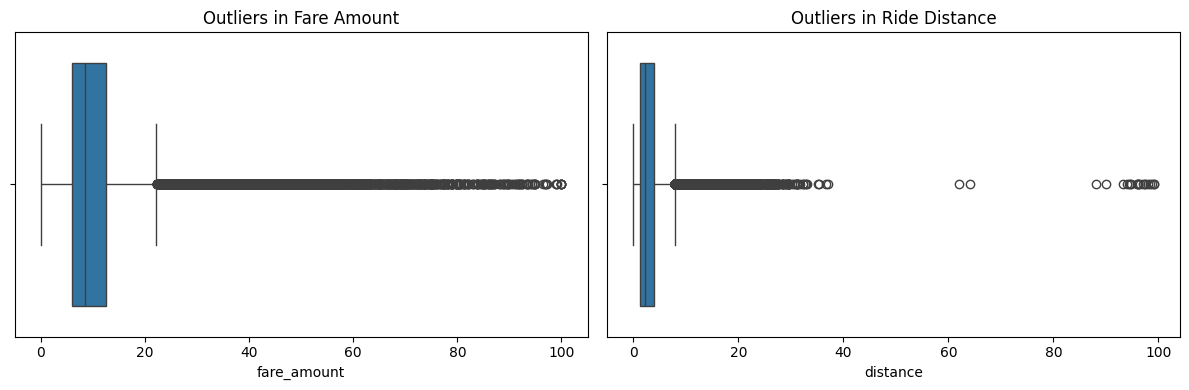

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["fare_amount"])
plt.title("Outliers in Fare Amount")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["distance"])
plt.title("Outliers in Ride Distance")

plt.tight_layout()
plt.show()

In [ ]:
Q1 = df[["fare_amount", "distance"]].quantile(0.25)
Q3 = df[["fare_amount", "distance"]].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = (
    (df["fare_amount"] < lower["fare_amount"]) |
    (df["fare_amount"] > upper["fare_amount"]) |
    (df["distance"] < lower["distance"]) |
    (df["distance"] > upper["distance"])
)

print("Number of outlier rows:", outliers.sum())

Number of outlier rows: 19400
Percentage of outlier rows: 10.05 %


In [12]:
df = df[
    df["fare_amount"].between(
        lower["fare_amount"], upper["fare_amount"]
    ) &
    df["distance"].between(
        lower["distance"], upper["distance"]
    )
].copy()

print("Shape after removing IQR outliers:", df.shape)

Shape after removing IQR outliers: (173720, 13)


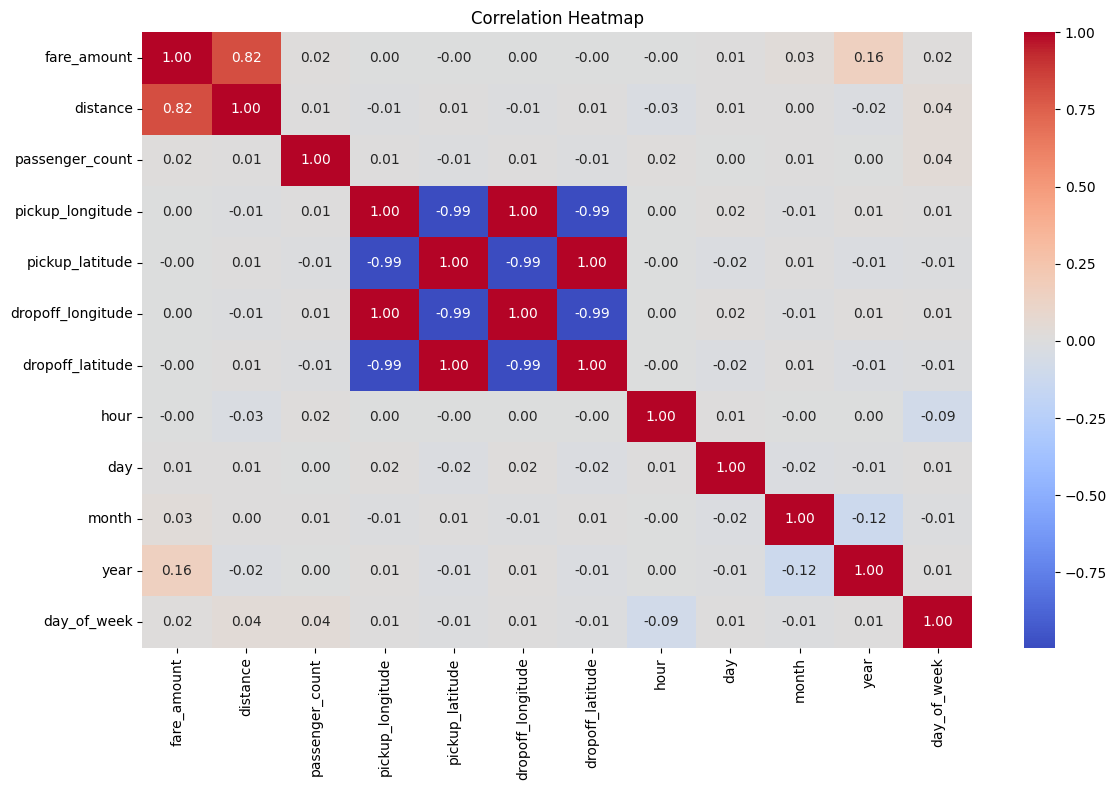

In [13]:
features = [
    "fare_amount", "distance", "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "hour", "day", "month", "year", "day_of_week"
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
X = df[
    [
        "distance",
        "pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude",
        "passenger_count",
        "hour", "day", "month", "year", "day_of_week"
    ]
]

y = df["fare_amount"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


Training samples: 40000
Testing samples: 10000


In [15]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [16]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score:", r2_score(y_test, lr_pred))

print("\nRandom Forest")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

Comparative Model Performance:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.5103,2.1192,0.6999
1,Random Forest,1.3564,1.9379,0.7491
